<a href="https://colab.research.google.com/github/stacykeago-pergolux/Last-mile-SMK/blob/main/TICKET%20589.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Delivery date present in all 5 carriers

In [ ]:
# vs code
# Item 1: “Every line in order_lines_deliveries_l whose order was delivered by one of the 5 carriers has its delivery date.”

# Build model in vs code to che
dbt build -s lastmile_deliveries_st order_lines_deliveries_l
# Results:   Done. PASS=8 WARN=1 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=9

#### check each carrier to see which did not pass the checks. (Rocket shipping 24 lines missing dates
)


In [ ]:
# check each carrier to see which did not pass the checks
#SNOWFLAKE
with shipments as (
    select order_id as order_name, carrier, stage, delivered_date
    from DEV_STACYKEAGON.s_staging.lastmile_deliveries_st
    where shipment_type = 'delivery'
    qualify row_number() over (
        partition by carrier, coalesce(carrier_ref, order_id)
        order by run_date desc, _loaded_at desc) = 1
),
delivered_orders as (   -- orders where every non-canceled shipment is delivered
    select order_name, any_value(carrier) as carrier
    from shipments
    where coalesce(stage, '') <> 'canceled'
    group by order_name
    having count_if(delivered_date is not null or stage = 'delivered') = count(*)
),
matched as (
    select d.carrier, d.order_name, o.shopify_order_id
    from delivered_orders d
    left join PROD_DB.l_logic.orders_l o on o.order_name = d.order_name
)
select
    m.carrier,
    count(distinct m.order_name)                                         as delivered_orders,
    count(distinct iff(m.shopify_order_id is null, m.order_name, null))  as orders_not_found_in_shopify,
    count(l.order_line_id)                                               as lines_in_model,
    count(l.delivered_date)                                              as lines_with_delivery_date,
    count_if(l.order_line_id is not null and l.delivered_date is null)   as lines_missing_date
from matched m
left join DEV_STACYKEAGON.l_logic.order_lines_deliveries_l l
    on l.shopify_order_id::varchar = m.shopify_order_id::varchar
group by m.carrier
order by m.carrier;

### delivered without dates


In [ ]:
with latest as (
    select *
    from DEV_STACYKEAGON.s_staging.lastmile_deliveries_st
    where shipment_type = 'delivery'
    qualify row_number() over (
        partition by carrier, coalesce(carrier_ref, order_id)
        order by run_date desc, _loaded_at desc) = 1
)
select
    carrier,
    count(*) as delivered_shipments,
    count_if(delivered_date is null and delivered_latest_date is null) as delivered_without_date,
    round(100 * delivered_without_date / delivered_shipments, 1) as pct_without_date
from latest
where stage = 'delivered'
group by carrier
order by carrier;

# 2. Lines without carrier data stay in the model, with an empty delivery date.

In [ ]:
#how many lines have no carrier data
# SNOWFLAKE
select
    count(*)                                         as total_lines,
    count_if(not has_carrier_data)                   as lines_without_carrier_data,
    count_if(not has_carrier_data and delivered_date is not null)       as no_carrier_but_has_date,
    count_if(not has_carrier_data and (
           delivery_carrier is not null
        or first_delivered_date is not null
        or delivery_shipment_count <> 0
        or delivered_shipment_count <> 0
        or is_fully_delivered
        or is_partly_delivered))                     as no_carrier_but_other_values
from DEV_STACYKEAGON.l_logic.order_lines_deliveries_l;

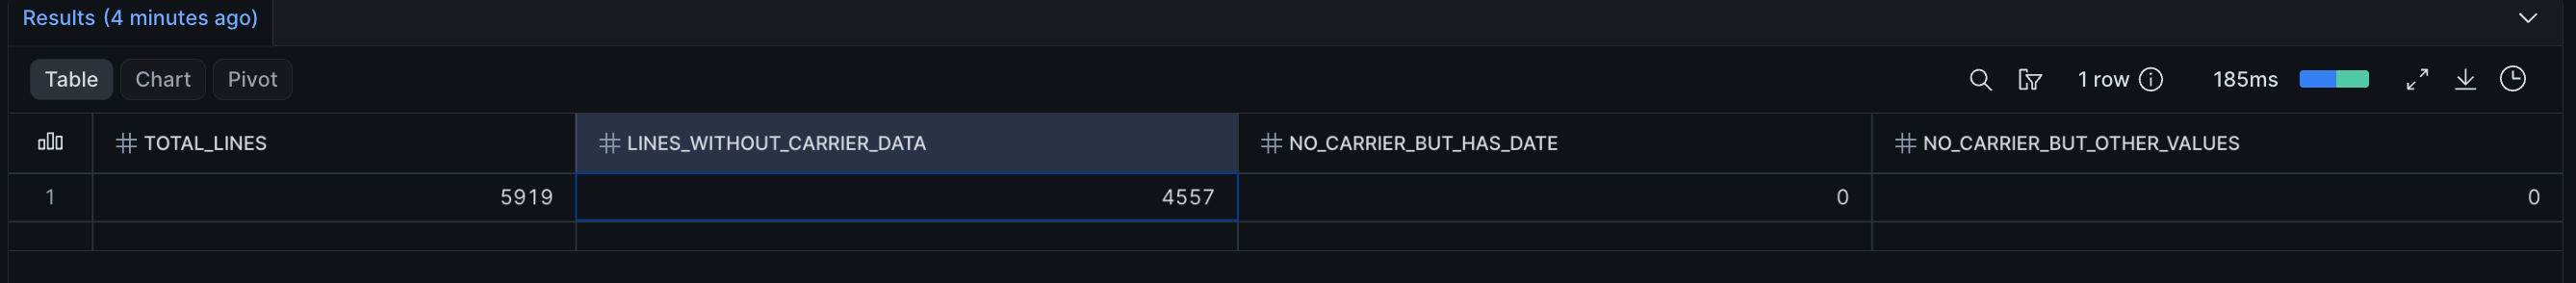